In [17]:
%run "/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/code/Initialization/Initialization.ipynb"

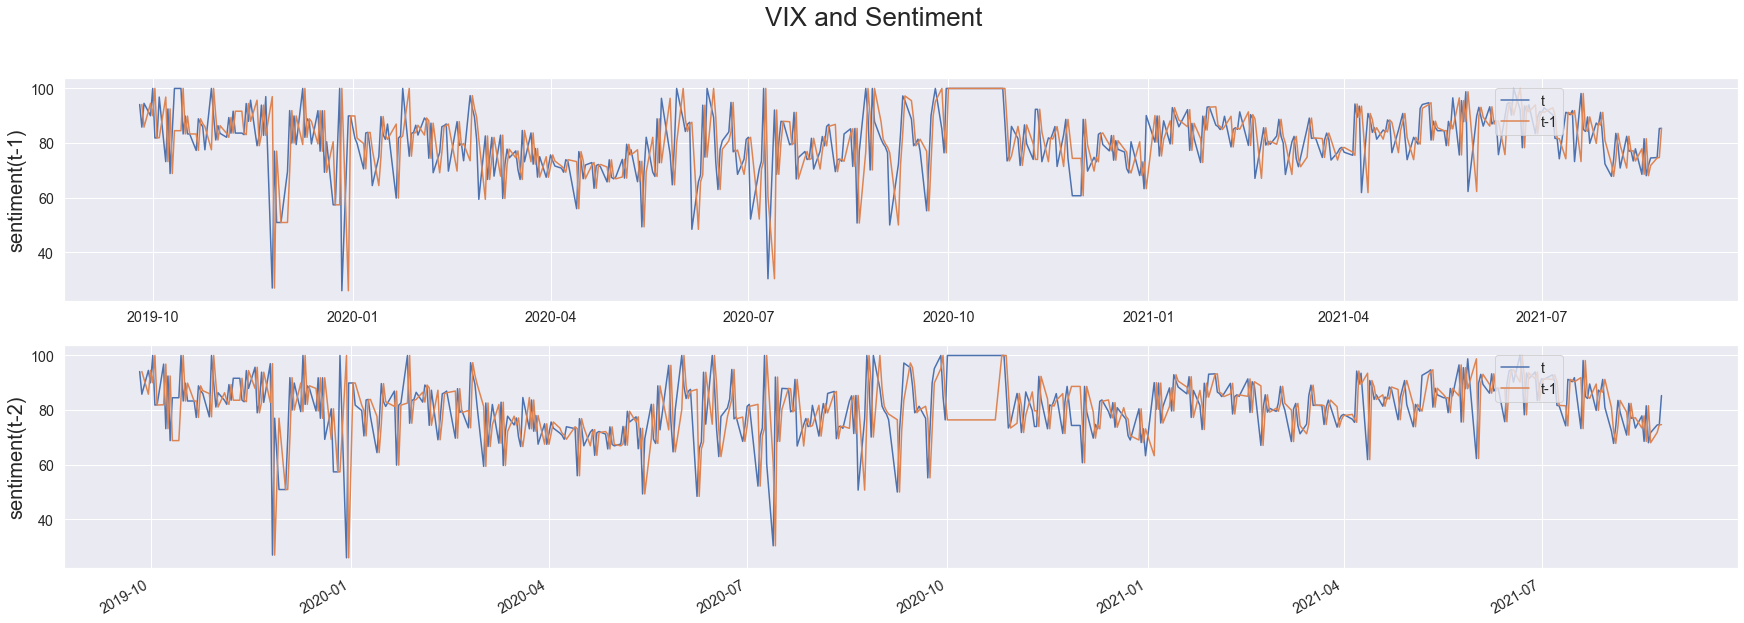

In [19]:
fig, axs = plt.subplots(2, figsize=(30,10))
fig.suptitle('VIX and Sentiment', size=26)
fig.autofmt_xdate()

axs[0].set_ylabel("sentiment", size=20)
axs[0].tick_params(axis='both', which='both',labelbottom=True)
l1 = axs[0].plot(df['sentiment'])

axs[0].set_ylabel("sentiment(t-1)", size=20)
axs[0].tick_params(axis='both', which='both',labelbottom=True)
l2 = axs[0].plot(df['sentiment(t-1)'])

labels=['t', 't-1']
axs[0].legend([l1, l2], labels=labels, loc='right', bbox_to_anchor=(0.9, 0.85))

axs[1].set_ylabel("sentiment(t-1)", size=20)
axs[1].tick_params(axis='both', which='both',labelbottom=True)
l1 = axs[1].plot(df['sentiment(t-1)'])

axs[1].set_ylabel("sentiment(t-2)", size=20)
axs[1].tick_params(axis='both', which='both',labelbottom=True)
l2 = axs[1].plot(df['sentiment(t-2)'])

labels=['t', 't-1']
axs[1].legend([l1, l2], labels=labels, loc='right', bbox_to_anchor=(0.9, 0.85))
plt.show()

AttributeError: 'Figure' object has no attribute 'update_xaxes'

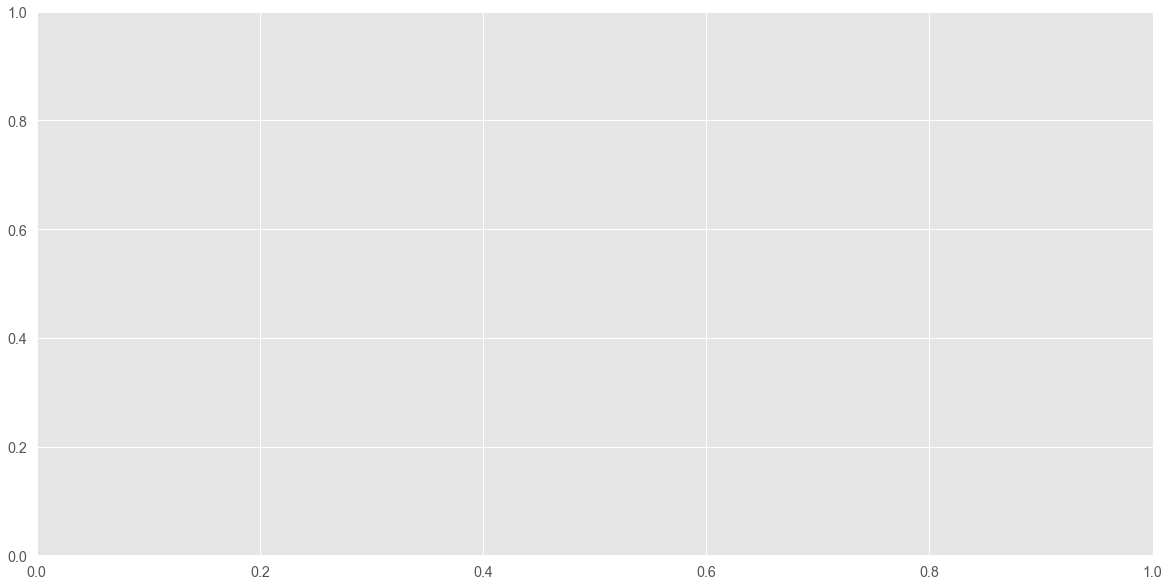

In [24]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime
import pandas as pd
import math
# % matplotlib inline

def timestr_to_num(timestr):
    return mdates.date2num(datetime.strptime('0' + timestr if timestr[1] == ':' else timestr,  "%d-%m-%Y %I:%M:%S %p"))

plt.style.use('ggplot')
# df = pd.read_csv('zpp00141_new.csv')
columns = ['Operation short text', 'Operation/Activity', 'Earl. start / time', 'Latest finish / time', 'Earl. start / time2', 'Latest finish / time2']
rows = [['Sentiment Ln Return', '0250', '26-08-2021 4:00:00 PM', '27-08-2021 4:00:00 PM', '27-08-2021 4:00:00 PM', '28-08-2021 4:00:00 PM'],
        ['Sentiment Ln Return 09:00-16:00', '0250', '27-08-2021 9:00:00 AM', '27-08-2021 4:00:00 PM', '28-08-2021 9:00:00 AM', '28-08-2021 4:00:00 PM'],
        ['Sentiment Ln Return 16:00-09:00', '0250', '27-08-2021 4:00:00 AM', '27-08-2021 4:00:00 PM', '28-08-2021 9:00:00 AM', '28-08-2021 4:00:00 PM'],
        ['VIX Ln Return', '0250', '27-08-2021 3:59:00 PM', '27-08-2021 4:00:00 PM', '28-08-2021 3:59:00 PM', '28-08-2021 4:00:00 PM'],
        ['S&P500 Ln Return', '0250', '27-08-2021 3:59:00 PM', '28-08-2021 4:00:00 PM', '26-08-2021 3:59:00 PM', '26-08-2021 4:00:00 PM'],]

df = pd.DataFrame(data=rows, columns=columns)
df.rename(columns={"Earl. start / time": "start", "Latest finish / time": "finish","Earl. start / time2": "start2", "Latest finish / time2": "finish2"}, inplace=True)
df['Operation/Activity'] = df['Operation/Activity'].astype(int)
df.sort_values('Operation/Activity', ascending=True, inplace=True, ignore_index=True)

fig, ax = plt.subplots(figsize=(20,10))

#colors = plt.cm.tab10.colors  # get a list of 10 colors
cmap = plt.cm.get_cmap('plasma_r')
colors = ["#0343DF"]   # get a list of 10 colors

previous_start = math.inf  # 'previous_start' helps to indicate we're starting again from the left
color_start = 0
row = df.loc[0]
left = timestr_to_num(row.start)
right = timestr_to_num(row.finish)
left2 = timestr_to_num(row.start2)
right2 = timestr_to_num(row.finish2)

ax.barh(0, left=left, width=right - left, height=0.2, color="#0343DF")
ax.barh(0, left=left2, width=right2 - left2, height=0.2, color="#0343DF")








previous_start = left
ax.set_xlim(timestr_to_num('26-08-2021 4:30:00 AM'), timestr_to_num('29-08-2021 4:30:00 PM'))

ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m-%Y %I:%M:%S %p"))  # display ticks as hours and minutes
# ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))  # set a tick every hour
ax.set_xlabel('Date')
# ax.set_ylabel('Operation')
ax.set_ylim(len(df), -1)  # set the limits and reverse the order
ax.set_yticks(range(len(df)))
# ax.set_yticklabels(list(df['Operation/Activity']))
ax.set_yticklabels(list(df['Operation short text']))
ax.fmt_xdata = mdates.DateFormatter("%d-%m-%Y %I:%M:%S %p")
now = '27-08-2021 4:00:00 PM'#datetime.now().strftime("%d-%m-%Y %I:%M:%S %p")
# ax.axvline(x=timestr_to_num(now),color='r')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
def plot_function(x, ax):
    ax = graph[x]
    ax.set_xlabel(x, weight='bold')
    return serotype_df.xs(x).plot(kind='bar', stacked='True', ax=ax, legend=False)

n_subplots = len(serotype_df.index.levels[0])
fig, axes = plt.subplots(nrows=1, ncols=n_subplots, sharey=True, figsize=(14, 8))  # width, height

graph = dict(zip(serotype_df.index.levels[0], axes))
plots = list(map(lambda x: plot_function(x, graph[x]), graph))
ax.tick_params(axis='both', which='both', length=0)
fig.subplots_adjust(wspace=0)

plt.legend()
plt.show()

(<Figure size 900x244.8 with 3 Axes>,
 array([<AxesSubplot:ylabel='2020'>, <AxesSubplot:ylabel='2021'>],
       dtype=object))

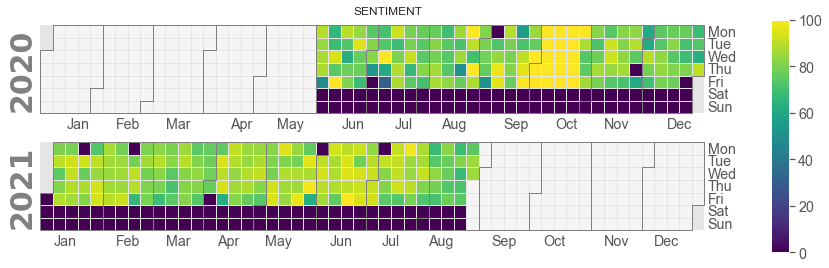

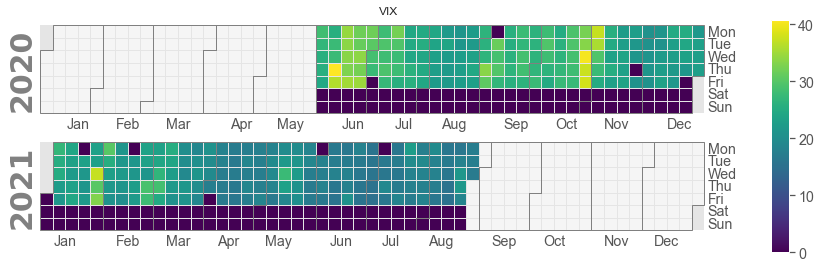

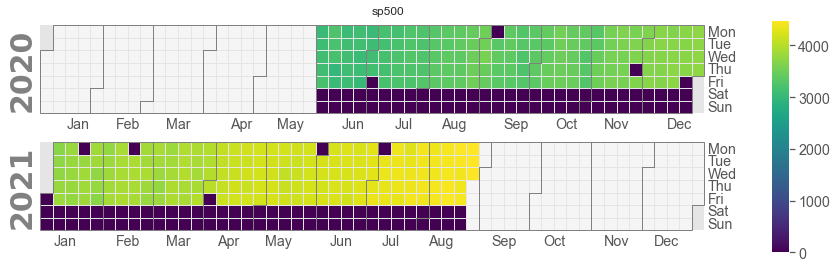

In [92]:
import calplot
import numpy as np; np.random.seed(sum(map(ord, 'calplot')))
import pandas as pd

all_days = pd.date_range('1/6/2020', periods=730, freq='D')
days = np.random.choice(all_days, 500)
events = df_part3.sentiment#pd.Series(np.random.randn(len(days)), index=days)
calplot.calplot(events, suptitle="SENTIMENT")

events = df_part3.vix#pd.Series(np.random.randn(len(days)), index=days)
calplot.calplot(events, suptitle="VIX")

events = df_part3.sp500#pd.Series(np.random.randn(len(days)), index=days)
calplot.calplot(events, suptitle="sp500")

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime
import pandas as pd
import math
# % matplotlib inline

def timestr_to_num(timestr):
    return mdates.date2num(datetime.strptime('0' + timestr if timestr[1] == ':' else timestr, '%I:%M:%S %p'))

plt.style.use('ggplot')
# df = pd.read_csv('zpp00141_new.csv')
columns = ['Operation short text', 'Operation/Activity', 'Earl. start / time', 'Latest finish / time']
rows = [['Mount right racks', '0250', '7:00:00 AM', '9:22:00 AM'],
        ['Mount right side motion unit carriage', '0251', '9:22:00 AM', '10:30:00 AM'],
        ['Mount left side motion unit carriage', '0252', '10:30:00 AM', '11:17:00 AM'],
        ['Install motion unit complete', '0253', '11:17:00 AM', '1:01:00 PM'],
        ['Move machine to next step + EPA', '0254', '1:01:00 PM', '3:30:00 PM'],
        ['Mount Left Racks', '0200', '7:00:00 AM', '9:12:00 AM'],
        ['Mount cable motor & Lubricate guide carr', '0201', '9:12:00 AM', '9:44:00 AM'],
        ['Mount suction components', '0202', '9:44:00 AM', '11:04:00 AM'],
        ['Mount extraction', '0203', '11:04:00 AM', '12:34:00 PM'],
        ['Mount temporary diamond plates', '0204', '12:34:00 PM', '1:04:00 PM'],
        ['Mount piping inside', '0205', '1:04:00 PM', '1:44:00 PM'],
        ['Move Machine to next step + EPA', '0206', '1:44:00 PM', '3:30:00 PM']]
df = pd.DataFrame(data=rows, columns=columns)
df.rename(columns={"Earl. start / time": "start", "Latest finish / time": "finish"}, inplace=True)

df['Operation/Activity'] = df['Operation/Activity'].astype(int)
df.sort_values('Operation/Activity', ascending=True, inplace=True, ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 5))

#colors = plt.cm.tab10.colors  # get a list of 10 colors
cmap = plt.cm.get_cmap('plasma_r')
colors = [cmap(i/9) for i in range(10)]   # get a list of 10 colors

previous_start = math.inf  # 'previous_start' helps to indicate we're starting again from the left
color_start = 0
for row in df.itertuples():
    left = timestr_to_num(row.start)
    right = timestr_to_num(row.finish)
    if left <= previous_start:
        color_start = row.Index
    ax.barh(row.Index, left=left, width=right - left, height=1, color=colors[(row.Index - color_start) % len(colors)])
    previous_start = left
ax.set_xlim(timestr_to_num('7:00:00 AM'), timestr_to_num('4:30:00 PM'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # display ticks as hours and minutes
ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))  # set a tick every hour
ax.set_xlabel('Time')
ax.set_ylabel('Operation')
ax.set_ylim(len(df), -1)  # set the limits and reverse the order
ax.set_yticks(range(len(df)))
# ax.set_yticklabels(list(df['Operation/Activity']))
ax.set_yticklabels(list(df['Operation short text']))

now = datetime.now().strftime('%I:%M:%S %p')
ax.axvline(x=timestr_to_num(now),color='r')

plt.tight_layout()
plt.show()